In [218]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.linear_model import PassiveAggressiveRegressor

data = pd.read_csv("Instagram data.csv", encoding = 'latin1')
print(data.head())

   Impressions  From Home  From Hashtags  From Explore  From Other  Saves  \
0         3920       2586           1028           619          56     98   
1         5394       2727           1838          1174          78    194   
2         4021       2085           1188             0         533     41   
3         4528       2700            621           932          73    172   
4         2518       1704            255           279          37     96   

   Comments  Shares  Likes  Profile Visits  Follows  \
0         9       5    162              35        2   
1         7      14    224              48       10   
2        11       1    131              62       12   
3        10       7    213              23        8   
4         5       4    123               8        0   

                                             Caption  \
0  Here are some of the most important data visua...   
1  Here are some of the best data science project...   
2  Learn how to train a machine learni

In [219]:
data.isnull().sum()
data = data.dropna()


In [220]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Impressions     119 non-null    int64
 1   From Home       119 non-null    int64
 2   From Hashtags   119 non-null    int64
 3   From Explore    119 non-null    int64
 4   From Other      119 non-null    int64
 5   Saves           119 non-null    int64
 6   Comments        119 non-null    int64
 7   Shares          119 non-null    int64
 8   Likes           119 non-null    int64
 9   Profile Visits  119 non-null    int64
 10  Follows         119 non-null    int64
 11  Caption         119 non-null    str  
 12  Hashtags        119 non-null    str  
dtypes: int64(11), str(2)
memory usage: 12.2 KB


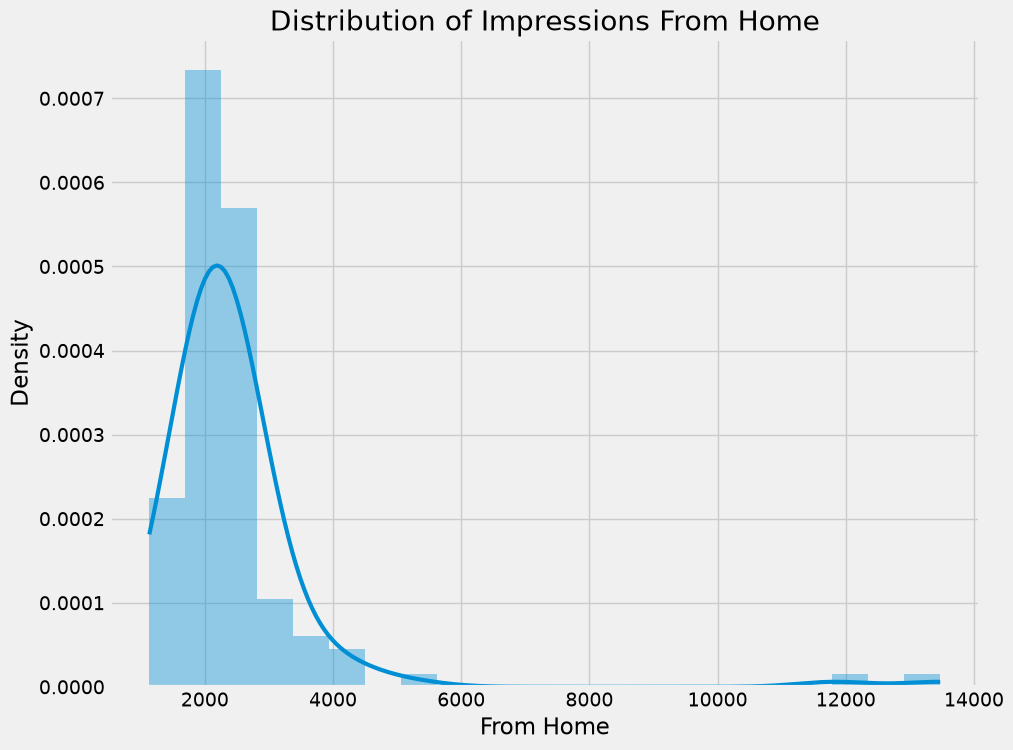

In [ ]:
plt.figure(figsize=(10, 8))
plt.style.use('fivethirtyeight')
plt.title("Distribution of Impressions From Home")

# Use histplot but force the legacy aesthetics
sns.histplot(
    data['From Home'], 
    kde=True, 
    stat="density", 
    edgecolor="none",       
    alpha=0.4,             
    line_kws={'linewidth': 3} 
)

plt.show()

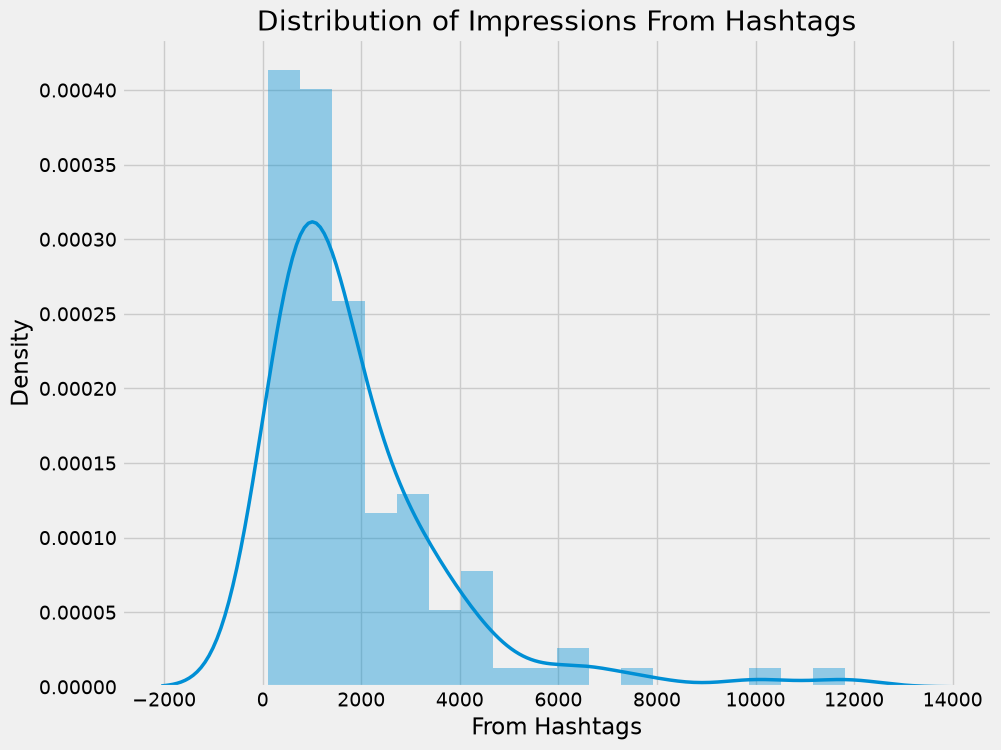

In [ ]:
plt.figure(figsize=(10, 8))
plt.title("Distribution of Impressions From Hashtags")


sns.histplot(
    data['From Hashtags'], 
    kde=True, 
    stat="density", 
    edgecolor="none", 
    alpha=0.4,
    line_kws={'linewidth': 2.5},
    kde_kws={'cut': 3} 
)

plt.show()

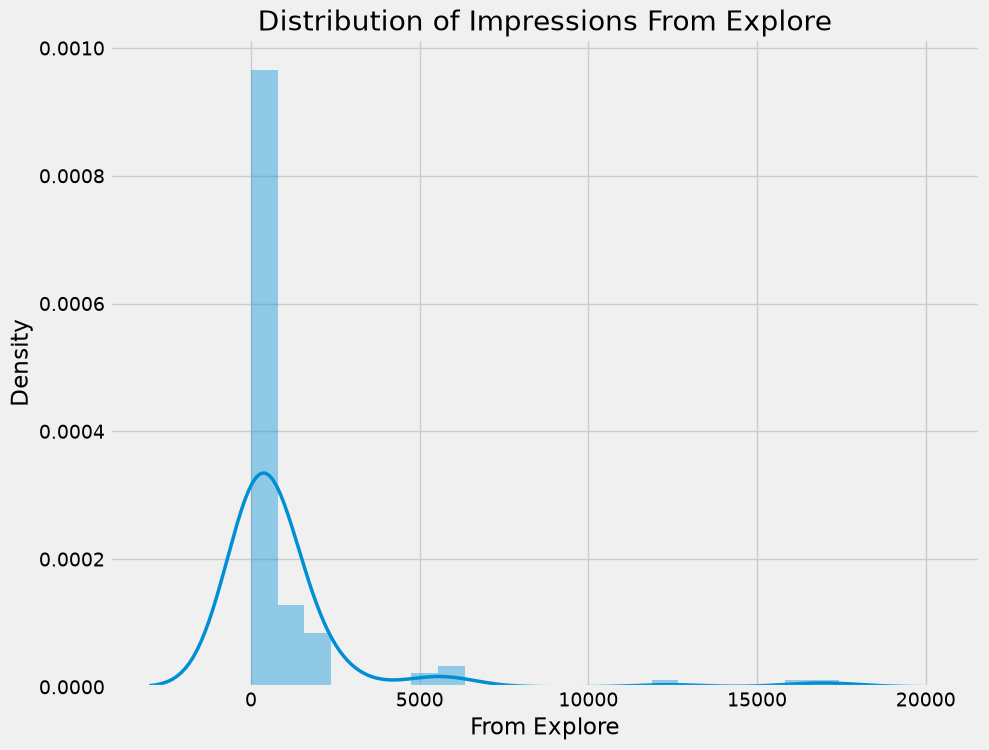

In [ ]:
plt.figure(figsize=(10, 8))
plt.title("Distribution of Impressions From Explore")


sns.histplot(
    data['From Explore'], 
    kde=True, 
    stat="density", 
    edgecolor="none", 
    alpha=0.4,
    line_kws={'linewidth': 2.5},
    kde_kws={'cut': 3}
)

plt.show()

In [224]:
%pip install nbformat>=4.2.0

Note: you may need to restart the kernel to use updated packages.


In [225]:
home = data["From Home"].sum()
hashtags = data["From Hashtags"].sum()
explore = data["From Explore"].sum()
other = data["From Other"].sum()

labels = ['From Home', 'From Hashtags', 'From Explore', 'Other']
values = [home, hashtags, explore, other]

fig = px.pie(
    data, 
    values=values, 
    names=labels, 
    title='Impressions on Instagram Posts From Various Sources', 
    hole=0.5
)
fig.show()

In [226]:
figure = px.scatter(data_frame = data, x="Impressions",
                    y="Likes", size="Likes", trendline="ols", 
                    title = "Relationship Between Likes and Impressions")
figure.show()

In [227]:
figure = px.scatter(data_frame = data, x="Impressions",
                    y="Comments", size="Comments", trendline="ols", 
                    title = "Relationship Between Comments and Total Impressions")
figure.show()

In [228]:
figure = px.scatter(data_frame = data, x="Impressions",
                    y="Shares", size="Shares", trendline="ols", 
                    title = "Relationship Between Shares and Total Impressions")
figure.show()

In [229]:
figure = px.scatter(data_frame = data, x="Impressions",
                    y="Saves", size="Saves", trendline="ols", 
                    title = "Relationship Between Post Saves and Total Impressions")
figure.show()

In [230]:
correlation = data.corr(numeric_only=True)
print(correlation["Impressions"].sort_values(ascending=False))
print(correlation["Impressions"].sort_values(ascending=False))

Impressions       1.000000
From Explore      0.893607
Follows           0.889363
Likes             0.849835
From Home         0.844698
Saves             0.779231
Profile Visits    0.760981
Shares            0.634675
From Other        0.592960
From Hashtags     0.560760
Comments         -0.028524
Name: Impressions, dtype: float64
Impressions       1.000000
From Explore      0.893607
Follows           0.889363
Likes             0.849835
From Home         0.844698
Saves             0.779231
Profile Visits    0.760981
Shares            0.634675
From Other        0.592960
From Hashtags     0.560760
Comments         -0.028524
Name: Impressions, dtype: float64


In [231]:
conversion_rate = (data["Follows"].sum() / data["Profile Visits"].sum()) * 100
print(conversion_rate)

41.00265604249668


In [232]:
figure = px.scatter(data_frame = data, x="Profile Visits",
                    y="Follows", size="Follows", trendline="ols", 
                    title = "Relationship Between Profile Visits and Followers Gained")
figure.show()

In [233]:
x = np.array(data[['Likes', 'Saves', 'Comments', 'Shares', 
                   'Profile Visits', 'Follows']])
y = np.array(data["Impressions"])
xtrain, xtest, ytrain, ytest = train_test_split(x, y, 
                                                test_size=0.2, 
                                                random_state=42)

In [234]:
from sklearn.linear_model import SGDRegressor

model = SGDRegressor(
    loss='epsilon_insensitive', 
    penalty=None, 
    learning_rate='pa1', 
    eta0=1.0
)

model.fit(xtrain, ytrain)
model.score(xtest, ytest)

0.9017078402555936

In [235]:
# Features = [['Likes','Saves', 'Comments', 'Shares', 'Profile Visits', 'Follows']]
features = np.array([[282.0, 233.0, 4.0, 9.0, 165.0, 54.0]])
model.predict(features)

array([9661.9310114])